# Capstone — mirrors your deployed research paper

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

In [1]:
print("""RESEARCH QUESTION
Using only what is known before the last 30 days, can we rank a client's pages so the ones about to lose 20%+ of their search impressions come first, and do it better than a transparent rule an editor could write by hand?

THE DECISION IT SUPPORTS
A content reviewer has a few hours and hundreds of pages per client. The question they actually face is "which 10 pages do I open first?". A good ranking means those hours go to pages that are losing visibility. A bad one wastes editor time on pages that were fine, or misses the ones that were slipping (lost traffic, and changes made to pages that didnt need them).

A CONCRETE CASE
A page that had ~1,400 impressions in days 31-60, down from ~2,500 the month before, 4 months old, and almost no clicks. Is it next? My rule says "sliding + visible + young = 4/4". The model says ~0.8 risk. The page then lost 19.8% of its impressions in the next 30 days, just short of the 20% line. That one case already holds most of this paper: the signal is real, the label is a hard cut, and the output can only ever be decision-support.""")

RESEARCH QUESTION
Using only what is known before the last 30 days, can we rank a client's pages so the ones about to lose 20%+ of their search impressions come first, and do it better than a transparent rule an editor could write by hand?

THE DECISION IT SUPPORTS
A content reviewer has a few hours and hundreds of pages per client. The question they actually face is "which 10 pages do I open first?". A good ranking means those hours go to pages that are losing visibility. A bad one wastes editor time on pages that were fine, or misses the ones that were slipping (lost traffic, and changes made to pages that didnt need them).

A CONCRETE CASE
A page that had ~1,400 impressions in days 31-60, down from ~2,500 the month before, 4 months old, and almost no clicks. Is it next? My rule says "sliding + visible + young = 4/4". The model says ~0.8 risk. The page then lost 19.8% of its impressions in the next 30 days, just short of the 20% line. That one case already holds most of this paper: t

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [2]:
"""Which data, which windows, what was left out. Everything here is the public starter slice, no client names, urls or queries exist in it, and only aggregates and pseudonymized ids leave this notebook."""

import sys
sys.path.insert(0, "../scripts")
sys.path.insert(0, "../../scripts")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import lane_features as lf
import lane_baseline as lb
from ml_utils import normalize, percentile_rank
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.metrics import roc_auc_score

raw = lf.load_raw()
df = lf.build_features(raw)
X = lf.feature_matrix(df)
y = df["is_declining_label"].to_numpy()

rows_per_client = df.groupby("client_id").size()
nested = int((raw["impressions_90d"] < raw["impressions_last_30d"] + raw["impressions_prev_30d"]).sum())
print(f"""release: data/raw/content_refresh_anonymized.csv (the anonymized starter slice shipped with the repo), {raw.shape[0]:,} rows x {raw.shape[1]} columns.
unit: one row = one page. {df['client_id'].nunique()} pseudonymized clients, {rows_per_client.min()} to {rows_per_client.max():,} pages each (biggest client = {rows_per_client.max() / len(df):.0%} of rows).
windows (trailing, no calendar dates): days 61-90 back | days 31-60 back (prev_30d) | days 1-30 back (last_30d = label window). windows nest exactly, rows that break it: {nested}.
label: is_declining_label = impressions last 30d < 0.8 x previous 30d (trend_direction == 'down'), base rate {y.mean():.1%} ({y.sum():,} pages).
prediction moment: day -30. features = content metadata + days 31-90 only ({len(lf.NUMERIC_FEATURES)} numeric, {len(lf.CATEGORICAL_FEATURES)} categorical, {X.shape[1]} columns after one-hot).
excluded (w03 contract, 28 of 44 columns): every 90 day total and 90 day rate (ctr, avg_position, days_with_impressions, engagement, scroll, ai traffic) because a third of their window IS the label window; days_since_last_update ({(raw['days_since_last_update'] < 30).mean():.0%} of pages updated inside the label window); trend_direction / trend_pct (the label); generation metadata (provider/model); duplicates and buckets; ids (split/join only).
not used: the full warehouse release on Hugging Face. this lane stays on the starter slice, so every number below is about these {df['client_id'].nunique()} clients and this one window.""")

release: data/raw/content_refresh_anonymized.csv (the anonymized starter slice shipped with the repo), 30,000 rows x 44 columns.
unit: one row = one page. 32 pseudonymized clients, 3 to 7,008 pages each (biggest client = 23% of rows).
windows (trailing, no calendar dates): days 61-90 back | days 31-60 back (prev_30d) | days 1-30 back (last_30d = label window). windows nest exactly, rows that break it: 0.
label: is_declining_label = impressions last 30d < 0.8 x previous 30d (trend_direction == 'down'), base rate 54.2% (16,262 pages).
prediction moment: day -30. features = content metadata + days 31-90 only (16 numeric, 3 categorical, 28 columns after one-hot).
excluded (w03 contract, 28 of 44 columns): every 90 day total and 90 day rate (ctr, avg_position, days_with_impressions, engagement, scroll, ai traffic) because a third of their window IS the label window; days_since_last_update (68% of pages updated inside the label window); trend_direction / trend_pct (the label); generation met

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

In [3]:
"""Assumptions, features, label, baseline, validation design, and the leakage checks, re-run here so the paper's numbers come from one run."""

print("""ASSUMPTIONS
- the 90 / 60 / 30 day windows nest (checked, 0 rows break it), so days 61-90 = 90d - last_30d - prev_30d is the real count for that window.
- word_count and keyword metadata describe the page as it was before day -30 (soft for word_count on pages edited later, noted).
- pages from one client share hidden character, so validation must hold whole clients out.

FEATURES (lane_features.py): keyword context (search volume, competition, cpc, has-keyword flag), word count + measured flag, age at day -30, log impressions / clicks / sessions for days 31-60 and 61-90, momentum into day -30 (log ratio of the two), ctr in days 31-60, a no-prior-traffic flag, content type, intent, competition level.

BASELINE (lane_baseline.py, frozen in w04): 0-4 points, sliding into day -30 = 2, visible (100+ impressions) = 1, under a year old = 1, ties broken by impressions at stake. built from the one signal that held in both client halves of the w04 audit (momentum). age and length beliefs did not hold (OPPOSITE / MIXED) and the page-one aging flag was FALSE inside clients.

MODEL: logistic regression on standardized features (picked in w05 over a depth-3 tree, random forest and gradient boosting, it had the best top of the list and the steadiest folds).

VALIDATION: 5-fold GroupKFold by client, every client is held out exactly once, metrics per fold then averaged. a random 80/20 row split is shown only to measure how optimistic it is. no time split exists (one snapshot), time is handled by the day -30 feature cut.""")

def logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

folds = list(GroupKFold(n_splits=5).split(X, y, groups=df["client_id"]))

def grouped_cv(features, shuffle_seed=None):
    aucs, p50s = [], []
    for a, b in folds:
        y_fit = y[a] if shuffle_seed is None else np.random.default_rng(shuffle_seed).permutation(y[a])
        s = logreg().fit(features.iloc[a], y_fit).predict_proba(features.iloc[b])[:, 1]
        aucs.append(roc_auc_score(y[b], s))
        p50s.append(lf.precision_at_k(y[b], s, 50))
    return np.mean(aucs), np.mean(p50s)

leak_checks = {
    "final features (honest)": grouped_cv(X),
    "+ trend_pct (planted leak, harness check)": grouped_cv(X.assign(trend_pct=raw["trend_pct"].fillna(0))),
    "+ raw impressions_90d (window arithmetic leak)": grouped_cv(X.assign(impressions_90d=np.log1p(raw["impressions_90d"]))),
    "+ 90d ctr, avg_position, days_with_impressions (overlap)": grouped_cv(X.assign(ctr=raw["ctr"], avg_position=raw["avg_position"], days_with_impressions=raw["days_with_impressions"])),
    "shuffled training labels (control, mean of 5)": tuple(np.mean([grouped_cv(X, shuffle_seed=s) for s in range(5)], axis=0)),
}
leak_table = pd.DataFrame(leak_checks, index=["AUC", "P@50"]).T.round(3)
leak_table["base rate"] = round(y.mean(), 3)
print("LEAKAGE CHECKS (5-fold grouped by client):")
display(leak_table)
print("ids in features:", [c for c in X.columns if c.endswith("_id")], "| product flags in the file:", [c for c in raw.columns if c in ["health_score", "priority_score", "action_type", "needs_ctr_fix", "is_quick_win"]])

ASSUMPTIONS
- the 90 / 60 / 30 day windows nest (checked, 0 rows break it), so days 61-90 = 90d - last_30d - prev_30d is the real count for that window.
- word_count and keyword metadata describe the page as it was before day -30 (soft for word_count on pages edited later, noted).
- pages from one client share hidden character, so validation must hold whole clients out.

FEATURES (lane_features.py): keyword context (search volume, competition, cpc, has-keyword flag), word count + measured flag, age at day -30, log impressions / clicks / sessions for days 31-60 and 61-90, momentum into day -30 (log ratio of the two), ctr in days 31-60, a no-prior-traffic flag, content type, intent, competition level.

BASELINE (lane_baseline.py, frozen in w04): 0-4 points, sliding into day -30 = 2, visible (100+ impressions) = 1, under a year old = 1, ties broken by impressions at stake. built from the one signal that held in both client halves of the w04 audit (momentum). age and length beliefs did not

LEAKAGE CHECKS (5-fold grouped by client):


,AUC,P@50,base rate
final features (honest),0.695,0.792,0.542
"+ trend_pct (planted leak, harness check)",0.999,1.000,0.542
+ raw impressions_90d (window arithmetic leak),0.892,0.992,0.542
"+ 90d ctr, avg_position, days_with_impressions (overlap)",0.751,0.892,0.542
"shuffled training labels (control, mean of 5)",0.495,0.464,0.542


ids in features: [] | product flags in the file: []


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [4]:
"""Model vs baseline, same folds, same rows, base rate in every row. The reference starter baseline (scripts/02 formula) is added for context. The reference random forest is left out on purpose: it uses 90 day features that overlap the label window, so its number isnt comparable."""

reference_score = (0.40 * percentile_rank(np.log1p(df["impressions_90d"]))
                   + 0.30 * percentile_rank(df["days_since_last_update"])
                   + 0.25 * (1 - normalize(df["avg_position"].clip(lower=1, upper=50))) * percentile_rank(np.log1p(df["impressions_90d"])) * (df["avg_position"] > 0)
                   + 0.05 * (1 - percentile_rank(df["word_count"])) * percentile_rank(np.log1p(df["impressions_90d"]))).to_numpy()
rule_score = lb.baseline_score(df).to_numpy()
oof = np.zeros(len(df))
per_fold = []
for k, (a, b) in enumerate(folds, start=1):
    oof[b] = logreg().fit(X.iloc[a], y[a]).predict_proba(X.iloc[b])[:, 1]
    for name, s in [("logistic regression", oof[b]), ("my rule baseline", rule_score[b]), ("reference starter baseline", reference_score[b])]:
        per_fold.append({"fold": k, "method": name, "P@20": lf.precision_at_k(y[b], s, 20), "P@50": lf.precision_at_k(y[b], s, 50),
                         "P@200": lf.precision_at_k(y[b], s, 200), "AUC": roc_auc_score(y[b], s), "base rate": y[b].mean()})
per_fold = pd.DataFrame(per_fold)
mean = per_fold.groupby("method")[["P@20", "P@50", "P@200", "AUC", "base rate"]].mean()
std = per_fold.groupby("method")[["P@20", "P@50", "P@200", "AUC"]].std()
results = mean.copy()
for col in ["P@20", "P@50", "P@200", "AUC"]:
    results[col] = [f"{m:.3f} +- {s:.3f}" for m, s in zip(mean[col], std[col])]
results["base rate"] = mean["base rate"].map(lambda v: f"{v:.3f}")
results = results.reindex(["logistic regression", "my rule baseline", "reference starter baseline"])
print("RESULTS, 5-fold grouped by client (mean +- std over folds):")
display(results)

lr_f = per_fold[per_fold["method"] == "logistic regression"].set_index("fold")
rule_f = per_fold[per_fold["method"] == "my rule baseline"].set_index("fold")
wins = int((lr_f["P@50"] > rule_f["P@50"]).sum())

tr_idx, te_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=lf.SEED, stratify=y)
s_rand = logreg().fit(X.iloc[tr_idx], y[tr_idx]).predict_proba(X.iloc[te_idx])[:, 1]
rand_auc, rand_p50 = roc_auc_score(y[te_idx], s_rand), lf.precision_at_k(y[te_idx], s_rand, 50)

lift = []
for cid, g in df.assign(score=oof).groupby("client_id"):
    if len(g) >= 50 and g["is_declining_label"].nunique() == 2:
        lift.append({"model top 10": g.nlargest(10, "score")["is_declining_label"].mean(),
                     "rule top 10": g.assign(r=lb.baseline_score(g)).nlargest(10, "r")["is_declining_label"].mean(),
                     "client base rate": g["is_declining_label"].mean()})
lift = pd.DataFrame(lift)

print(f"""reading the table:
- the model beats the frozen rule at P@50 in {wins} of 5 folds ({lr_f['P@50'].mean():.2f} vs {rule_f['P@50'].mean():.2f}), and both are far above the reference starter baseline ({mean.loc['reference starter baseline', 'P@50']:.2f}) and the {y.mean():.0%} base rate.
- AUC is modest ({lr_f['AUC'].mean():.2f}): the model is much better at the top of the list than at sorting the whole middle, which is fine for a review queue.
- a random 80/20 row split would have reported AUC {rand_auc:.3f} / P@50 {rand_p50:.2f}, the grouped split gives {lr_f['AUC'].mean():.3f} / {lr_f['P@50'].mean():.2f}. the gap is client memorization.
- inside each client with 50+ pages ({len(lift)} clients), the model's top 10 averaged {lift['model top 10'].mean():.0%} declined vs {lift['rule top 10'].mean():.0%} for the rule's top 10 and a {lift['client base rate'].mean():.0%} client base rate.
- the w02 target (P@50 >= 0.80) is met on {int((lr_f['P@50'] >= 0.80).sum())} of 5 folds, not reliably.""")

RESULTS, 5-fold grouped by client (mean +- std over folds):


,P@20,P@50,P@200,AUC,base rate
method,,,,,
logistic regression,0.820 +- 0.115,0.792 +- 0.125,0.793 +- 0.094,0.695 +- 0.077,0.544
my rule baseline,0.700 +- 0.127,0.692 +- 0.131,0.693 +- 0.162,0.670 +- 0.099,0.544
reference starter baseline,0.420 +- 0.115,0.464 +- 0.173,0.497 +- 0.169,0.599 +- 0.107,0.544


reading the table:
- the model beats the frozen rule at P@50 in 4 of 5 folds (0.79 vs 0.69), and both are far above the reference starter baseline (0.46) and the 54% base rate.
- AUC is modest (0.69): the model is much better at the top of the list than at sorting the whole middle, which is fine for a review queue.
- a random 80/20 row split would have reported AUC 0.737 / P@50 0.88, the grouped split gives 0.695 / 0.79. the gap is client memorization.
- inside each client with 50+ pages (24 clients), the model's top 10 averaged 75% declined vs 65% for the rule's top 10 and a 53% client base rate.
- the w02 target (P@50 >= 0.80) is met on 3 of 5 folds, not reliably.


## 5. Limitations

*What this work cannot claim.*

In [5]:
print("""LIMITATIONS (what this work cannot claim)
1. One snapshot, no later month. this is an out-of-sample ranking across clients, not a forecast tested on future data. a time split was impossible on this file.
2. Correlation, not cause. nothing here shows that refreshing a page stops a decline. the paper's 'refresh multiplier' style claims need a before/after with an untouched comparison group, which this data cant give.
3. The label is a hard +-20% cut on GSC impressions. pages that dropped 10-20% count as 'not declining' (a quarter of the model's top-200 misses in w05 were these near misses), and tiny pages flip on a few impressions.
4. 32 clients, very unequal. one client is ~23% of rows, P@50 swings by +-0.12 across folds, and misses cluster by client (site-wide events look like page problems).
5. Pre-filtered population: pages are 90+ days old with impressions AND sessions. new pages and zero-traffic pages are out of scope.
6. The starter slice only. none of this was rerun on the full warehouse release, so it says nothing yet about the other clients or other periods there.
7. Small soft spots in the features: word_count is measured at export, and a quarter of pages have no word count at all (handled with a flag).
8. Negative results are part of the result: older pages, thin pages and the page-one aging flag did NOT show more decline in this data. those beliefs should not drive the queue.""")

LIMITATIONS (what this work cannot claim)
1. One snapshot, no later month. this is an out-of-sample ranking across clients, not a forecast tested on future data. a time split was impossible on this file.
2. Correlation, not cause. nothing here shows that refreshing a page stops a decline. the paper's 'refresh multiplier' style claims need a before/after with an untouched comparison group, which this data cant give.
3. The label is a hard +-20% cut on GSC impressions. pages that dropped 10-20% count as 'not declining' (a quarter of the model's top-200 misses in w05 were these near misses), and tiny pages flip on a few impressions.
4. 32 clients, very unequal. one client is ~23% of rows, P@50 swings by +-0.12 across folds, and misses cluster by client (site-wide events look like page problems).
5. Pre-filtered population: pages are 90+ days old with impressions AND sessions. new pages and zero-traffic pages are out of scope.
6. The starter slice only. none of this was rerun on the full w

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [6]:
"""The playbook output (w07), regenerated from the out-of-fold scores above: ranked inside each client, reason codes in words, an action and a confidence band. Then the recommendations in plain words."""

codes = lb.reason_codes(df)
codes = codes.where(~((df["impressions_prev_30d"] >= 100) & (df["ctr_prev30"] < 0.1)), codes + "|impressions_without_clicks")
codes = codes.where(~(df["content_age_days"] < 180), codes + "|young_page")
has = lambda name: codes.str.contains(name)
queue = df[["client_id", "content_id", "is_declining_label"]].assign(
    decline_risk=oof,
    rule_points=lb.baseline_points(df),
    reason_codes=codes.str.replace("general_review|", "", regex=False),
    suggested_action=np.select([has("no_prior_traffic"), has("already_sliding") & has("visible_before"), has("impressions_without_clicks"), has("recent_spike")],
                               ["no_action", "refresh_review", "snippet_and_intent_review", "watch_spike"], "monitor"),
)
queue["confidence"] = np.select(
    [(queue["decline_risk"] >= 0.80) & (queue["rule_points"] >= 3), (queue["decline_risk"] >= 0.70) | (queue["rule_points"] == 4), queue["decline_risk"] >= 0.50],
    ["high", "medium", "low"], "none")
queue.loc[queue["suggested_action"] == "no_action", "confidence"] = "none"
queue["client_rank"] = queue.groupby("client_id")["decline_risk"].rank(ascending=False, method="first").astype(int)
client_index = {c: f"client_{i:02d}" for i, c in enumerate(df.groupby("client_id").size().sort_values(ascending=False).index, start=1)}
queue["client"] = queue["client_id"].map(client_index)

top3 = queue[queue["client_rank"] <= 3].sort_values(["client", "client_rank"])
with pd.option_context("display.max_colwidth", None, "display.width", 220):
    display(top3[top3["client"].isin(["client_01", "client_02", "client_03"])][["client", "client_rank", "decline_risk", "suggested_action", "confidence", "reason_codes"]].round(3))

bands = queue.groupby("confidence")["is_declining_label"].agg(declined="mean", pages="size").reindex(["high", "medium", "low", "none"]).round(3)
display(bands)

print(f"""RANKED RECOMMENDATIONS (for a FlyRank editor, tomorrow)
1. Work the queue per client, top 10 first. inside a client the model's top 10 averaged {lift['model top 10'].mean():.0%} declined vs a {lift['client base rate'].mean():.0%} base rate. dont use one global list, it ends up being one client.
2. Before opening pages, look at the client. if most of its top 10 are flagged, check for a site-wide cause (migration, tracking, seasonality) first, misses cluster by client.
3. 'refresh_review' pages first (already sliding + visible): check the keyword demand and who ranks now, then refresh. 'high' confidence pages declined {bands.loc['high', 'declined']:.0%} of the time here.
4. 'snippet_and_intent_review' pages next: they show up in search but almost nobody clicks. the cheap first move is the title / description / intent match, not a full rewrite.
5. Dont queue pages for being old or short. in this data that pointed the wrong way or nowhere.
6. Log every refresh with its date. thats the only way the next cycle can compare refreshed vs untouched pages and finally say something about whether refreshing helps.""")

,client,client_rank,decline_risk,suggested_action,confidence,reason_codes
9649,client_01,1,0.875,snippet_and_intent_review,medium,visible_before|still_settling|impressions_without_clicks|young_page
6409,client_01,2,0.874,snippet_and_intent_review,medium,visible_before|still_settling|impressions_without_clicks|young_page
22522,client_01,3,0.869,refresh_review,high,already_sliding|visible_before|still_settling|impressions_without_clicks|young_page
1841,client_02,1,0.968,refresh_review,high,already_sliding|visible_before|still_settling|impressions_without_clicks
8114,client_02,2,0.965,refresh_review,high,already_sliding|visible_before|still_settling
17970,client_02,3,0.960,refresh_review,high,already_sliding|visible_before|still_settling|impressions_without_clicks
27610,client_03,1,0.870,refresh_review,high,already_sliding|visible_before|impressions_without_clicks
12578,client_03,2,0.865,snippet_and_intent_review,medium,visible_before|impressions_without_clicks
26589,client_03,3,0.865,refresh_review,high,already_sliding|visible_before|impressions_without_clicks


,declined,pages
confidence,,
high,0.759,1220
medium,0.698,11703
low,0.532,10667
none,0.233,6410


RANKED RECOMMENDATIONS (for a FlyRank editor, tomorrow)
1. Work the queue per client, top 10 first. inside a client the model's top 10 averaged 75% declined vs a 53% base rate. dont use one global list, it ends up being one client.
2. Before opening pages, look at the client. if most of its top 10 are flagged, check for a site-wide cause (migration, tracking, seasonality) first, misses cluster by client.
3. 'refresh_review' pages first (already sliding + visible): check the keyword demand and who ranks now, then refresh. 'high' confidence pages declined 76% of the time here.
4. 'snippet_and_intent_review' pages next: they show up in search but almost nobody clicks. the cheap first move is the title / description / intent match, not a full rewrite.
5. Dont queue pages for being old or short. in this data that pointed the wrong way or nowhere.
6. Log every refresh with its date. thats the only way the next cycle can compare refreshed vs untouched pages and finally say something about whe

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

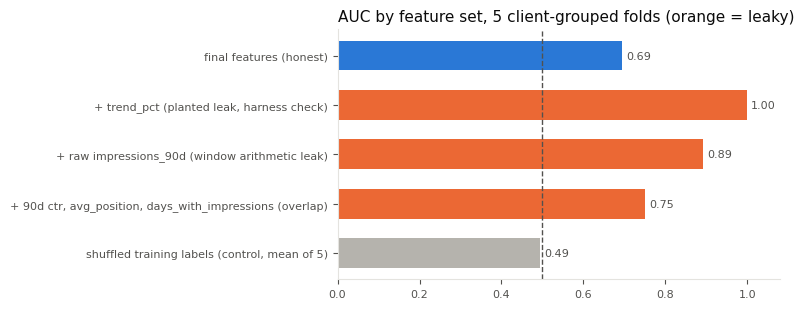

message: every feature set that touches the label window scores higher (AUC 0.75-1.00), but every one of those gains comes from peeking into the label window, which a real queue on day -30 cant do. the honest set sits at 0.69, shuffled labels at 0.49.


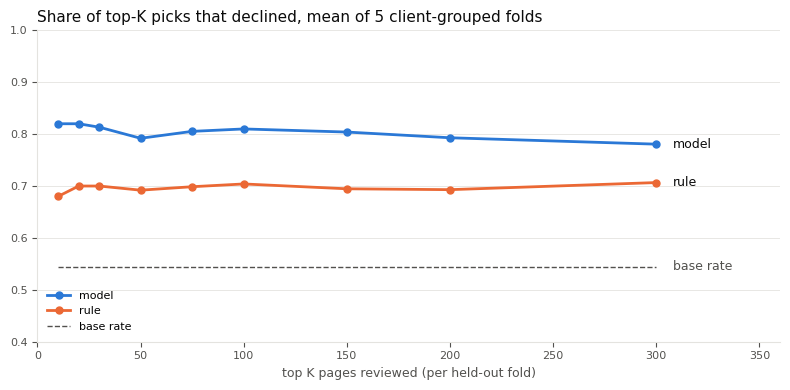

message: at every K the model's picks decline more often than the rule's (0.79 vs 0.69 at K=50), and both sit well above the 54% base rate.

ABSTRACT (written last, goes first on the page):
Which of a client's pages are about to lose search visibility, and can we rank them before it happens? Using an anonymized slice of 30,000 pages from 32 clients, we predicted whether a page's impressions would fall 20% or more in the next 30 days using only information available before that window. A logistic regression was compared against a transparent 0-4 point rule on 5 client-grouped folds, after showing that the 90 day totals the starter pipeline relies on overlap the label window (adding one of them lifts AUC from 0.69 to 0.89 without any real skill). The model's top 50 picks per fold declined 79% of the time (+-12%) versus 69% for the rule and a 54% base rate, and inside a client its top 10 averaged 75% versus a 53% client base rate. The output is a per-client review queue with reason codes,


REPRODUCE FROM A FRESH CLONE
  pip install -r requirements.txt
  run in order (top to bottom): w03_data_contract, w03_feature_leakage_check (writes work/scripts/lane_features.py),
  w04_signal_audit, w04_baseline_score (writes work/scripts/lane_baseline.py), w05_model, w06_validation_audit,
  w07_action_playbook, capstone. both .py files are committed, so the capstone also runs on its own.
  seed 42 everywhere.

ARTIFACTS FOR THE PAGE
  ..\figures\capstone_leakage.png  (44 KB)
  ..\figures\capstone_precision_at_k.png  (41 KB)
  ..\figures\w04_distributions.png  (69 KB)
  ..\figures\w04_signal_tests.png  (63 KB)
  ..\figures\w07_action_mix.png  (28 KB)
  ..\figures\w07_precision_at_k.png  (40 KB)
  ..\outputs\capstone_results.md  (2 KB)
  ..\outputs\precision_at_k_table.md  (0 KB)
  ..\outputs\playbook_summary.json  (2 KB)
  ..\outputs\capstone_queue.csv  (3,685 KB)  <- local only, gitignored

data credit: FlyRank anonymized content-performance starter slice (data/raw/content_refresh_a

In [7]:
"""Charts and tables the deployed page will show. Each chart has one message, written under it. Everything here is aggregate, so it can be committed (only the csv queue stays local)."""

out_dir, fig_dir = Path("../outputs"), Path("../figures")
out_dir.mkdir(exist_ok=True)
fig_dir.mkdir(exist_ok=True)
INK, MUTED, GRID, BLUE, ORANGE, GRAY = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#eb6834", "#b5b3ad"

def tidy(ax):
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)

# chart 1: the leak chart, honest vs leaky feature sets
fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(leak_table.index)[::-1]
vals = leak_table["AUC"].to_numpy()[::-1]
colors = [BLUE if n.startswith("final") else (GRAY if n.startswith("shuffled") else ORANGE) for n in names]
ax.barh(names, vals, color=colors, height=0.6)
for i, v in enumerate(vals):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8, color=MUTED)
ax.axvline(0.5, color=MUTED, linestyle="--", linewidth=1)
ax.set_xlim(0, 1.08)
ax.set_title("AUC by feature set, 5 client-grouped folds (orange = leaky)", loc="left", fontsize=11, color=INK)
tidy(ax)
fig.tight_layout()
fig.savefig(fig_dir / "capstone_leakage.png", dpi=130)
plt.show()
leaky = leak_table.loc[[n for n in leak_table.index if n.startswith("+")], "AUC"]
print(f"message: every feature set that touches the label window scores higher (AUC {leaky.min():.2f}-{leaky.max():.2f}), but every one of those gains comes from peeking into the label window, which a real queue on day -30 cant do. "
      f"the honest set sits at {leak_table.loc['final features (honest)', 'AUC']:.2f}, shuffled labels at {leak_table.loc['shuffled training labels (control, mean of 5)', 'AUC']:.2f}.")

# chart 2: precision@K, model vs rule vs base rate
ks = [10, 20, 30, 50, 75, 100, 150, 200, 300]
curve = {"model": np.mean([[lf.precision_at_k(y[b], oof[b], k) for k in ks] for a, b in folds], axis=0),
         "rule": np.mean([[lf.precision_at_k(y[b], rule_score[b], k) for k in ks] for a, b in folds], axis=0),
         "base rate": np.mean([[y[b].mean()] * len(ks) for a, b in folds], axis=0)}
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, curve["model"], color=BLUE, linewidth=2, marker="o", markersize=5, label="model")
ax.plot(ks, curve["rule"], color=ORANGE, linewidth=2, marker="o", markersize=5, label="rule")
ax.plot(ks, curve["base rate"], color=MUTED, linewidth=1, linestyle="--", label="base rate")
for name, color in [("model", INK), ("rule", INK), ("base rate", MUTED)]:
    ax.text(ks[-1] + 8, curve[name][-1], name, color=color, va="center", fontsize=9)
ax.set_xlim(0, ks[-1] + 60)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("top K pages reviewed (per held-out fold)", color=MUTED, fontsize=9)
ax.set_title("Share of top-K picks that declined, mean of 5 client-grouped folds", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.6)
ax.legend(loc="lower left", frameon=False, fontsize=8)
tidy(ax)
fig.tight_layout()
fig.savefig(fig_dir / "capstone_precision_at_k.png", dpi=130)
plt.show()
print(f"message: at every K the model's picks decline more often than the rule's ({curve['model'][3]:.2f} vs {curve['rule'][3]:.2f} at K=50), and both sit well above the {curve['base rate'][0]:.0%} base rate.")

abstract = (f"Which of a client's pages are about to lose search visibility, and can we rank them before it happens? "
            f"Using an anonymized slice of {len(df):,} pages from {df['client_id'].nunique()} clients, we predicted whether a page's impressions would fall 20% or more in the next 30 days using only information available before that window. "
            f"A logistic regression was compared against a transparent 0-4 point rule on 5 client-grouped folds, after showing that the 90 day totals the starter pipeline relies on overlap the label window (adding one of them lifts AUC from {leak_table.loc['final features (honest)', 'AUC']:.2f} to {leak_table.loc['+ raw impressions_90d (window arithmetic leak)', 'AUC']:.2f} without any real skill). "
            f"The model's top 50 picks per fold declined {lr_f['P@50'].mean():.0%} of the time (+-{lr_f['P@50'].std():.0%}) versus {rule_f['P@50'].mean():.0%} for the rule and a {y.mean():.0%} base rate, and inside a client its top 10 averaged {lift['model top 10'].mean():.0%} versus a {lift['client base rate'].mean():.0%} client base rate. "
            f"The output is a per-client review queue with reason codes, meant as decision-support for where editors look first, not as a forecast of rankings or evidence that refreshing works.")
print("\nABSTRACT (written last, goes first on the page):\n" + abstract)

md = ["# Capstone results (generated by work/notebooks/capstone.ipynb)", "", "## Abstract", "", abstract, "",
      "## Results, 5-fold grouped by client (mean +- std)", "", "| method | P@20 | P@50 | P@200 | AUC | base rate |", "|---|---:|---:|---:|---:|---:|"]
md += [f"| {m} | {r['P@20']} | {r['P@50']} | {r['P@200']} | {r['AUC']} | {r['base rate']} |" for m, r in results.iterrows()]
md += ["", "## Leakage checks (AUC / P@50, 5-fold grouped)", "", "| feature set | AUC | P@50 |", "|---|---:|---:|"]
md += [f"| {n} | {r['AUC']:.3f} | {r['P@50']:.3f} |" for n, r in leak_table.iterrows()]
md += ["", "## Confidence bands (hindsight, out-of-fold)", "", "| band | declined | pages |", "|---|---:|---:|"]
md += [f"| {b} | {r['declined']:.3f} | {int(r['pages']):,} |" for b, r in bands.iterrows()]
md += ["", f"Random 80/20 row split for comparison: AUC {rand_auc:.3f}, P@50 {rand_p50:.2f}.",
       f"Within-client top 10 ({len(lift)} clients with 50+ pages): model {lift['model top 10'].mean():.2f}, rule {lift['rule top 10'].mean():.2f}, client base rate {lift['client base rate'].mean():.2f}.",
       f"Seeds: {lf.SEED}. pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}."]
(out_dir / "capstone_results.md").write_text("\n".join(md) + "\n", encoding="utf-8")

queue.drop(columns=["client_id"]).to_csv(out_dir / "capstone_queue.csv", index=False)

print("""
REPRODUCE FROM A FRESH CLONE
  pip install -r requirements.txt
  run in order (top to bottom): w03_data_contract, w03_feature_leakage_check (writes work/scripts/lane_features.py),
  w04_signal_audit, w04_baseline_score (writes work/scripts/lane_baseline.py), w05_model, w06_validation_audit,
  w07_action_playbook, capstone. both .py files are committed, so the capstone also runs on its own.
  seed 42 everywhere.

ARTIFACTS FOR THE PAGE""")
for p in sorted(fig_dir.glob("*.png")) + [out_dir / "capstone_results.md", out_dir / "precision_at_k_table.md", out_dir / "playbook_summary.json", out_dir / "capstone_queue.csv"]:
    if p.exists():
        print(f"  {p}  ({p.stat().st_size / 1024:,.0f} KB){'  <- local only, gitignored' if p.suffix == '.csv' else ''}")
print("\ndata credit: FlyRank anonymized content-performance starter slice (data/raw/content_refresh_anonymized.csv), used under DATA_USE.md.")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.